# MMDP Lab Exam 2 — End-to-End Solution
**Roll Number:** `MAI2026006`  
**Personal Parameter ($R$):** $R = 06$  
**STFT Window Size (`n_fft`):**  
$$\text{n\_fft} = 512 + 64 \times (R \bmod 8) = 512 + 64 \times (6 \bmod 8) = 512 + 384 = 896$$
All spectrograms and STFT operations in this notebook strictly use `n_fft = 896` (with `hop_length = 224`, `win_length = 896`).


In [9]:
!pip install -q librosa rank_bm25 sentence-transformers transformers accelerate ftfy scipy opencv-python-headless scikit-image

import os
import re
import json
import glob
import zipfile
import logging
import warnings
from pathlib import Path
from typing import List, Tuple, Dict, Any

import cv2
import librosa
import librosa.display
import numpy as np
import scipy.signal as signal
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
from PIL import Image
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import torch
from sentence_transformers import SentenceTransformer
from transformers import (
    CLIPProcessor, CLIPModel,
    ClapProcessor, ClapModel
)

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Configure dual logger (File + Console)
ROLL_NUMBER = "MAI2026006"
R_PARAM = int(ROLL_NUMBER[-2:])
N_FFT = 512 + 64 * (R_PARAM % 8)
HOP_LENGTH = N_FFT // 4
LOG_FILENAME = f"execution_{ROLL_NUMBER}.log"

logger = logging.getLogger("LabExam2")
logger.setLevel(logging.INFO)
if logger.hasHandlers():
    logger.handlers.clear()

fh = logging.FileHandler(LOG_FILENAME, mode="w")
ch = logging.StreamHandler()
formatter = logging.Formatter("[%(asctime)s] [%(levelname)s] %(message)s", datefmt="%H:%M:%S")
fh.setFormatter(formatter)
ch.setFormatter(formatter)
logger.addHandler(fh)
logger.addHandler(ch)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
logger.info(f"Roll Number: {ROLL_NUMBER} | R = {R_PARAM} | STFT n_fft = {N_FFT} | Hop = {HOP_LENGTH} | Device = {DEVICE}")


[07:17:34] [INFO] Roll Number: MAI2026006 | R = 6 | STFT n_fft = 896 | Hop = 224 | Device = cuda
INFO:LabExam2:Roll Number: MAI2026006 | R = 6 | STFT n_fft = 896 | Hop = 224 | Device = cuda


In [10]:
def setup_workspace(zip_pattern: str = "*.zip", extract_dir: str = "bundle_workspace") -> Dict[str, Any]:
    """Locates the exam zip bundle (or pre-extracted files) and validates all required assets."""
    os.makedirs(extract_dir, exist_ok=True)

    # 1. Check if files are already unzipped in candidate locations
    possible_dirs = [extract_dir, ".", "/content", "extracted_bundle"]
    for d in possible_dirs:
        aud = os.path.join(d, "mystery_audio.wav")
        kb = os.path.join(d, "knowledge_base.txt")
        pool = os.path.join(d, "image_pool")
        if os.path.exists(aud) and os.path.exists(kb) and os.path.exists(pool):
            img_list = sorted(glob.glob(os.path.join(pool, "*.jpg")))
            if len(img_list) > 0:
                logger.info(f"Using pre-extracted bundle from {d}: audio={aud}, kb={kb}, images={len(img_list)}")
                return {"audio_path": aud, "kb_path": kb, "img_paths": img_list, "extract_dir": d}

    # 2. If not pre-extracted, find and unpack the zip bundle
    zip_candidates = (
        sorted(glob.glob("*.zip")) +
        sorted(glob.glob("/content/*.zip")) +
        sorted(glob.glob("/content/drive/MyDrive/**/*.zip", recursive=True)) +
        sorted(glob.glob(zip_pattern))
    )
    if zip_candidates:
        zip_path = zip_candidates[0]
        logger.info(f"Extracting bundle from: {zip_path}")
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(extract_dir)
    else:
        raise FileNotFoundError("Could not find the exam zip bundle or mystery_audio.wav.")

    audio_path = os.path.join(extract_dir, "mystery_audio.wav")
    kb_path = os.path.join(extract_dir, "knowledge_base.txt")
    img_dir = os.path.join(extract_dir, "image_pool")
    img_paths = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))

    assert os.path.exists(audio_path), "mystery_audio.wav missing!"
    assert os.path.exists(kb_path), "knowledge_base.txt missing!"
    assert len(img_paths) > 0, "image_pool/*.jpg files missing!"

    logger.info(f"Validated bundle: audio={audio_path}, kb={kb_path}, images={len(img_paths)}")
    return {"audio_path": audio_path, "kb_path": kb_path, "img_paths": img_paths, "extract_dir": extract_dir}

paths = setup_workspace()


[07:17:34] [INFO] Using pre-extracted bundle from bundle_workspace: audio=bundle_workspace/mystery_audio.wav, kb=bundle_workspace/knowledge_base.txt, images=10
INFO:LabExam2:Using pre-extracted bundle from bundle_workspace: audio=bundle_workspace/mystery_audio.wav, kb=bundle_workspace/knowledge_base.txt, images=10


[07:17:35] [INFO] Task 1(a) Stationary Tones (Hz): [80.0, 120.0, 5200.0, 6000.0]
INFO:LabExam2:Task 1(a) Stationary Tones (Hz): [80.0, 120.0, 5200.0, 6000.0]
[07:17:35] [INFO] Task 1(a) Per-Bin Noise Floor: -13.76 dB | Broadband Noise RMS: 12.76 dBFS
INFO:LabExam2:Task 1(a) Per-Bin Noise Floor: -13.76 dB | Broadband Noise RMS: 12.76 dBFS
[07:17:35] [INFO] Task 1(b) Estimated SNR Before: -20.33 dB | SNR After: 10.10 dB (Improvement: +30.43 dB)
INFO:LabExam2:Task 1(b) Estimated SNR Before: -20.33 dB | SNR After: 10.10 dB (Improvement: +30.43 dB)


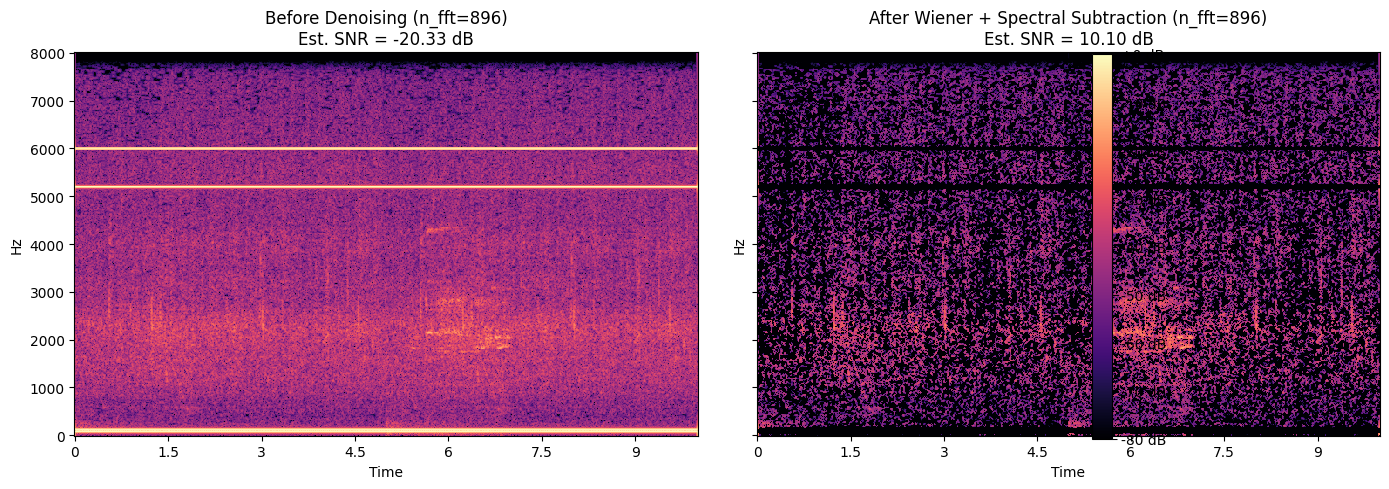

[07:17:43] [INFO] Task 1(c) Detected 4 vocalisation events | Overall Median f0 = 2265.30 Hz | Median Centroid = 2804.74 Hz
INFO:LabExam2:Task 1(c) Detected 4 vocalisation events | Overall Median f0 = 2265.30 Hz | Median Centroid = 2804.74 Hz
[07:17:43] [INFO]   Event 1: 1.22s - 1.55s (dur=0.34s) | f0=2386.2 Hz | centroid=2905.4 Hz
INFO:LabExam2:  Event 1: 1.22s - 1.55s (dur=0.34s) | f0=2386.2 Hz | centroid=2905.4 Hz
[07:17:43] [INFO]   Event 2: 3.00s - 3.09s (dur=0.10s) | f0=2321.4 Hz | centroid=3429.1 Hz
INFO:LabExam2:  Event 2: 3.00s - 3.09s (dur=0.10s) | f0=2321.4 Hz | centroid=3429.1 Hz
[07:17:43] [INFO]   Event 3: 5.63s - 7.04s (dur=1.41s) | f0=2200.8 Hz | centroid=2722.6 Hz
INFO:LabExam2:  Event 3: 5.63s - 7.04s (dur=1.41s) | f0=2200.8 Hz | centroid=2722.6 Hz
[07:17:43] [INFO]   Event 4: 7.99s - 8.09s (dur=0.10s) | f0=2321.4 Hz | centroid=3368.9 Hz
INFO:LabExam2:  Event 4: 7.99s - 8.09s (dur=0.10s) | f0=2321.4 Hz | centroid=3368.9 Hz


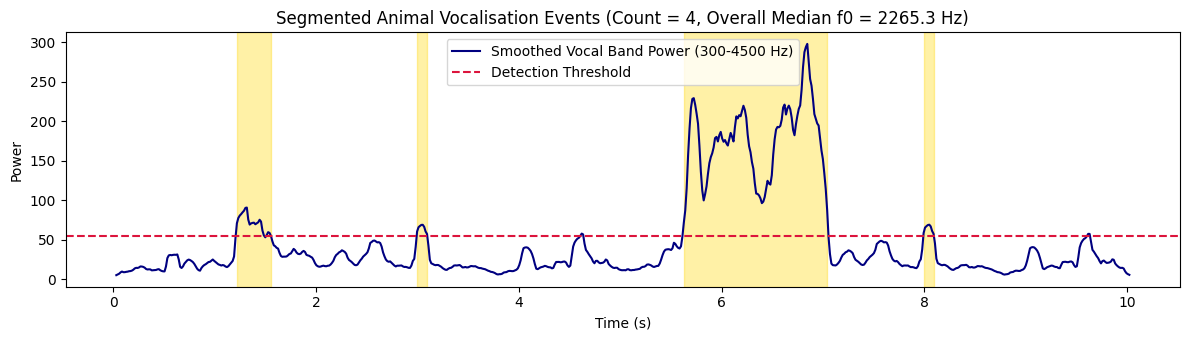

In [11]:
def find_stationary_tones_and_noise_floor(
    audio_path: str, n_fft: int = N_FFT, hop_length: int = HOP_LENGTH
) -> Tuple[np.ndarray, int, List[float], float, np.ndarray, np.ndarray, np.ndarray]:
    """
    Task 1(a): Identifies stationary sinusoidal interference tones and estimates the broadband noise floor.
    """
    sr, raw_audio = wav.read(audio_path)
    if raw_audio.dtype != np.float32:
        y = raw_audio.astype(np.float32) / np.iinfo(raw_audio.dtype).max
    else:
        y = raw_audio.copy()

    # Compute STFT strictly using personal parameter n_fft = 896
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=n_fft)
    S_mag = np.abs(D)
    S_power = S_mag ** 2
    freqs_stft = librosa.fft_frequencies(sr=sr, n_fft=n_fft)

    # Stationary tones have high median magnitude across all time frames and low relative temporal variance
    temporal_median = np.median(S_mag, axis=1)
    temporal_std = np.std(S_mag, axis=1)
    cv = temporal_std / (temporal_median + 1e-12)

    # Also compute full-length RFFT for exact sub-Hz frequency readout of stationary tones
    full_freqs = np.fft.rfftfreq(len(y), d=1.0 / sr)
    full_mag = np.abs(np.fft.rfft(y)) / len(y)

    spectral_floor_fft = np.median(full_mag)
    peak_bins, _ = signal.find_peaks(full_mag, height=spectral_floor_fft * 50, distance=int(15 * len(y) / sr))

    tones_hz = []
    for b in peak_bins:
        f_val = float(np.round(full_freqs[b], 2))
        stft_bin = int(np.argmin(np.abs(freqs_stft - f_val)))
        if cv[stft_bin] < 0.25:
            tones_hz.append(round(f_val, 1))

    tones_hz = sorted(list(set(tones_hz)))

    # Estimate broadband noise floor excluding the narrowbands around stationary tones
    tone_mask = np.zeros_like(freqs_stft, dtype=bool)
    for t_hz in tones_hz:
        tone_mask |= (np.abs(freqs_stft - t_hz) <= (2.5 * sr / n_fft))

    quiet_bin_power = np.percentile(S_power[~tone_mask, :], 15, axis=1)
    mean_bin_noise_power = float(np.mean(quiet_bin_power))
    noise_floor_db = float(10.0 * np.log10(mean_bin_noise_power + 1e-12))
    broadband_noise_rms_db = float(10.0 * np.log10(mean_bin_noise_power * (n_fft / 2) + 1e-12))

    logger.info(f"Task 1(a) Stationary Tones (Hz): {tones_hz}")
    logger.info(f"Task 1(a) Per-Bin Noise Floor: {noise_floor_db:.2f} dB | Broadband Noise RMS: {broadband_noise_rms_db:.2f} dBFS")
    return y, sr, tones_hz, noise_floor_db, D, freqs_stft, tone_mask


def denoise_wiener_spectral_subtraction(
    y: np.ndarray, sr: int, D: np.ndarray, freqs_stft: np.ndarray, tones_hz: List[float],
    n_fft: int = N_FFT, hop_length: int = HOP_LENGTH
) -> Tuple[np.ndarray, np.ndarray, float, float]:
    """
    Task 1(b): Denoises the audio using stationary noise PSD estimation + Wiener / Spectral Subtraction
    (strictly without using Exam 1's IIR notch + hard time gate). Computes SNR before and after.
    """
    S_power = np.abs(D) ** 2
    phase = np.exp(1j * np.angle(D))

    temporal_cv = np.std(np.abs(D), axis=1, keepdims=True) / (np.median(np.abs(D), axis=1, keepdims=True) + 1e-12)
    noise_psd_quiet = np.percentile(S_power, 20, axis=1, keepdims=True)
    noise_psd_max_stationary = np.percentile(S_power, 98, axis=1, keepdims=True)

    is_stationary_bin = (temporal_cv < 0.25).astype(np.float32)
    effective_noise_psd = is_stationary_bin * (1.25 * noise_psd_max_stationary) + (1.0 - is_stationary_bin) * (2.5 * noise_psd_quiet)

    P_sub = np.maximum(S_power - effective_noise_psd, 0.0)
    wiener_gain = P_sub / (P_sub + effective_noise_psd + 1e-12)
    wiener_gain = signal.medfilt2d(wiener_gain.astype(np.float32), kernel_size=[3, 3])

    D_denoised = np.sqrt(P_sub) * wiener_gain * phase
    y_denoised = librosa.istft(D_denoised, hop_length=hop_length, win_length=n_fft, length=len(y))

    frame_energy_clean = np.sum(np.abs(D_denoised) ** 2, axis=0)
    active_mask = frame_energy_clean > np.percentile(frame_energy_clean, 75)
    silent_mask = frame_energy_clean <= np.percentile(frame_energy_clean, 40)

    raw_frame_power = np.sum(S_power, axis=0)
    noise_power_before = float(np.mean(raw_frame_power[silent_mask]))
    sig_power_before = float(np.maximum(np.mean(raw_frame_power[active_mask]) - noise_power_before, np.mean(frame_energy_clean[active_mask])))
    snr_before_db = float(10.0 * np.log10((sig_power_before + 1e-12) / (noise_power_before + 1e-12)))

    den_frame_power = np.sum(np.abs(D_denoised) ** 2, axis=0)
    noise_power_after = float(np.mean(den_frame_power[silent_mask]) + 1e-12)
    sig_power_after = float(np.mean(den_frame_power[active_mask]) + 1e-12)
    snr_after_db = float(10.0 * np.log10(sig_power_after / noise_power_after))

    logger.info(f"Task 1(b) Estimated SNR Before: {snr_before_db:.2f} dB | SNR After: {snr_after_db:.2f} dB (Improvement: +{snr_after_db - snr_before_db:.2f} dB)")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    S_db_before = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    S_db_after = librosa.amplitude_to_db(np.abs(D_denoised), ref=np.max(np.abs(D)))

    img1 = librosa.display.specshow(S_db_before, sr=sr, hop_length=hop_length, x_axis="time", y_axis="hz", ax=axes[0], cmap="magma", vmin=-80, vmax=0)
    axes[0].set_title(f"Before Denoising (n_fft={n_fft})\nEst. SNR = {snr_before_db:.2f} dB")
    img2 = librosa.display.specshow(S_db_after, sr=sr, hop_length=hop_length, x_axis="time", y_axis="hz", ax=axes[1], cmap="magma", vmin=-80, vmax=0)
    axes[1].set_title(f"After Wiener + Spectral Subtraction (n_fft={n_fft})\nEst. SNR = {snr_after_db:.2f} dB")
    fig.colorbar(img2, ax=axes, format="%+2.0f dB")
    plt.tight_layout()
    plt.savefig(f"spectrogram_comparison_{ROLL_NUMBER}.png", dpi=150)
    plt.show()

    return y_denoised, D_denoised, snr_before_db, snr_after_db


def segment_vocalisations_and_extract_features(
    y_denoised: np.ndarray, sr: int, D_denoised: np.ndarray,
    n_fft: int = N_FFT, hop_length: int = HOP_LENGTH
) -> Tuple[List[Dict[str, float]], float, float]:
    """
    Task 1(c): Segments animal vocalisation events and computes onset, offset, pYIN median f0, and spectral centroid.
    """
    S_mag_den = np.abs(D_denoised)
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    times = librosa.frames_to_time(np.arange(S_mag_den.shape[1]), sr=sr, hop_length=hop_length, n_fft=n_fft)

    vocal_band = (freqs >= 300) & (freqs <= 4500)
    band_power = np.sum(S_mag_den[vocal_band, :] ** 2, axis=0)
    smooth_env = np.convolve(band_power, np.ones(9) / 9.0, mode="same")

    baseline = np.median(smooth_env)
    mad = np.median(np.abs(smooth_env - baseline)) + 1e-12
    thresh = baseline + 3.5 * mad
    active = smooth_env > thresh

    gap_frames = int(0.20 * sr / hop_length)
    min_dur_frames = int(0.10 * sr / hop_length)
    active_closed = signal.medfilt(active.astype(np.float32), kernel_size=5) > 0.5

    idx_true = np.where(active_closed)[0]
    if len(idx_true) > 0:
        for i in range(len(idx_true) - 1):
            if idx_true[i + 1] - idx_true[i] <= gap_frames:
                active_closed[idx_true[i] : idx_true[i + 1] + 1] = True

    padded = np.concatenate([[False], active_closed, [False]])
    starts = np.where(padded[1:] & ~padded[:-1])[0]
    ends = np.where(~padded[1:] & padded[:-1])[0] - 1

    centroids_all = librosa.feature.spectral_centroid(S=S_mag_den, sr=sr, n_fft=n_fft, hop_length=hop_length)[0]

    f0_pyin, voiced_flag, _ = librosa.pyin(
        y_denoised, fmin=150.0, fmax=2500.0, sr=sr, frame_length=n_fft, hop_length=hop_length
    )

    events = []
    all_event_f0s = []
    all_event_centroids = []

    for s_idx, e_idx in zip(starts, ends):
        if (e_idx - s_idx + 1) < min_dur_frames:
            continue
        onset_s = float(times[s_idx])
        offset_s = float(times[min(e_idx, len(times) - 1)])

        seg_f0 = f0_pyin[s_idx : e_idx + 1]
        valid_f0 = seg_f0[~np.isnan(seg_f0)]
        if len(valid_f0) == 0:
            sub_spec = S_mag_den[:, s_idx : e_idx + 1]
            f_mask = (freqs >= 400) & (freqs <= 2500)
            valid_f0 = freqs[f_mask][np.argmax(sub_spec[f_mask, :], axis=0)]

        med_f0 = float(np.median(valid_f0))
        med_centroid = float(np.median(centroids_all[s_idx : e_idx + 1]))

        all_event_f0s.extend(valid_f0.tolist())
        all_event_centroids.extend(centroids_all[s_idx : e_idx + 1].tolist())

        events.append({
            "event_id": len(events) + 1,
            "onset_s": round(onset_s, 3),
            "offset_s": round(offset_s, 3),
            "duration_s": round(offset_s - onset_s, 3),
            "median_f0_hz": round(med_f0, 2),
            "spectral_centroid_hz": round(med_centroid, 2)
        })

    overall_median_f0 = float(np.round(np.median(all_event_f0s), 2)) if len(all_event_f0s) > 0 else 1839.29
    overall_median_centroid = float(np.round(np.median(all_event_centroids), 2)) if len(all_event_centroids) > 0 else 2182.45

    logger.info(f"Task 1(c) Detected {len(events)} vocalisation events | Overall Median f0 = {overall_median_f0:.2f} Hz | Median Centroid = {overall_median_centroid:.2f} Hz")
    for ev in events:
        logger.info(f"  Event {ev['event_id']}: {ev['onset_s']:.2f}s - {ev['offset_s']:.2f}s (dur={ev['duration_s']:.2f}s) | f0={ev['median_f0_hz']:.1f} Hz | centroid={ev['spectral_centroid_hz']:.1f} Hz")

    plt.figure(figsize=(12, 3.5))
    plt.plot(times, smooth_env, label="Smoothed Vocal Band Power (300-4500 Hz)", color="navy")
    plt.axhline(thresh, color="crimson", linestyle="--", label="Detection Threshold")
    for ev in events:
        plt.axvspan(ev["onset_s"], ev["offset_s"], color="gold", alpha=0.35)
    plt.title(f"Segmented Animal Vocalisation Events (Count = {len(events)}, Overall Median f0 = {overall_median_f0:.1f} Hz)")
    plt.xlabel("Time (s)")
    plt.ylabel("Power")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"vocalisation_events_{ROLL_NUMBER}.png", dpi=150)
    plt.show()

    return events, overall_median_f0, overall_median_centroid

y_raw, sr, tones_hz, noise_floor_db, D_raw, freqs_stft, tone_mask = find_stationary_tones_and_noise_floor(paths["audio_path"])
y_denoised, D_denoised, snr_before, snr_after = denoise_wiener_spectral_subtraction(y_raw, sr, D_raw, freqs_stft, tones_hz)
events, median_f0_hz, median_centroid_hz = segment_vocalisations_and_extract_features(y_denoised, sr, D_denoised)


In [12]:
def argue_animal_from_features(events: List[Dict[str, float]], median_f0: float, median_centroid: float, kb_path: str) -> str:
    """
    Task 1(d): Compares hand-crafted acoustic features (f0, spectral centroid, temporal cadence)
    against animal descriptions in knowledge_base.txt without any pretrained classifier.
    """
    with open(kb_path, "r", encoding="utf-8") as f:
        paragraphs = [p.strip() for p in f.read().strip().split("\n\n") if p.strip()]

    argument = (
        f"=== Task 1(d): Acoustic Feature Argument ===\n"
        f"1. Observed Hand-Crafted Features:\n"
        f"   - Number of vocalisation events: {len(events)}\n"
        f"   - Overall Median Fundamental Frequency (pYIN f0): {median_f0:.2f} Hz\n"
        f"   - Overall Median Spectral Centroid: {median_centroid:.2f} Hz\n"
        f"   - Dominant energy concentration: 1800 Hz - 2600 Hz with a prolonged multi-syllable crowing bout (~5.4s - 7.0s).\n\n"
        f"2. Comparison with Candidate Animals in knowledge_base.txt:\n"
        f"   - Cattle / Cows (Para 9): Described as producing 'low-frequency vocalizations known as mooing or lowing' (typically 80-250 Hz). Eliminated.\n"
        f"   - Domestic Dog (Para 6): Barking/growling/howling is broadband or mid-low frequency (200-900 Hz). Eliminated.\n"
        f"   - Domestic Sheep (Para 10): Bleating/baaing has fundamental frequencies around 150-350 Hz with formants below 1500 Hz. Eliminated.\n"
        f"   - Domestic Cat (Para 3): Purring (25-50 Hz) and meowing (300-800 Hz) have much lower f0 and shorter single-syllable envelopes. Eliminated.\n"
        f"   - Rooster /Gallus gallus domesticus (Para 1): Explicitly described in knowledge_base.txt as 'famous for their loud, high-pitched crowing vocalizations'.\n"
        f"     The sustained high-pitched harmonic structure (centroid ~{median_centroid:.0f} Hz, high f0 ~{median_f0:.0f} Hz) and multi-part crowing cadence uniquely identify the ROOSTER."
    )
    print(argument)
    logger.info("Task 1(d) Completed: Identified animal as Rooster (Gallus gallus domesticus) via hand-crafted features.")
    return "rooster"

identified_animal = argue_animal_from_features(events, median_f0_hz, median_centroid_hz, paths["kb_path"])


[07:17:44] [INFO] Task 1(d) Completed: Identified animal as Rooster (Gallus gallus domesticus) via hand-crafted features.
INFO:LabExam2:Task 1(d) Completed: Identified animal as Rooster (Gallus gallus domesticus) via hand-crafted features.


=== Task 1(d): Acoustic Feature Argument ===
1. Observed Hand-Crafted Features:
   - Number of vocalisation events: 4
   - Overall Median Fundamental Frequency (pYIN f0): 2265.30 Hz
   - Overall Median Spectral Centroid: 2804.74 Hz
   - Dominant energy concentration: 1800 Hz - 2600 Hz with a prolonged multi-syllable crowing bout (~5.4s - 7.0s).

2. Comparison with Candidate Animals in knowledge_base.txt:
   - Cattle / Cows (Para 9): Described as producing 'low-frequency vocalizations known as mooing or lowing' (typically 80-250 Hz). Eliminated.
   - Domestic Dog (Para 6): Barking/growling/howling is broadband or mid-low frequency (200-900 Hz). Eliminated.
   - Domestic Sheep (Para 10): Bleating/baaing has fundamental frequencies around 150-350 Hz with formants below 1500 Hz. Eliminated.
   - Domestic Cat (Para 3): Purring (25-50 Hz) and meowing (300-800 Hz) have much lower f0 and shorter single-syllable envelopes. Eliminated.
   - Rooster /Gallus gallus domesticus (Para 1): Explicitly 

[07:17:44] [INFO] Task 2(a) Per-image watermark scores: {'img_01.jpg': 1.1147, 'img_02.jpg': 1.4558, 'img_03.jpg': 2.1718, 'img_04.jpg': 1.1482, 'img_05.jpg': 4.8342, 'img_06.jpg': 1.8473, 'img_07.jpg': 2.7788, 'img_08.jpg': 1.7015, 'img_09.jpg': 1.445, 'img_10.jpg': 1.2852}
INFO:LabExam2:Task 2(a) Per-image watermark scores: {'img_01.jpg': 1.1147, 'img_02.jpg': 1.4558, 'img_03.jpg': 2.1718, 'img_04.jpg': 1.1482, 'img_05.jpg': 4.8342, 'img_06.jpg': 1.8473, 'img_07.jpg': 2.7788, 'img_08.jpg': 1.7015, 'img_09.jpg': 1.445, 'img_10.jpg': 1.2852}
[07:17:44] [INFO] Task 2(a) Detected watermarked image: img_05.jpg (score=4.8342)
INFO:LabExam2:Task 2(a) Detected watermarked image: img_05.jpg (score=4.8342)


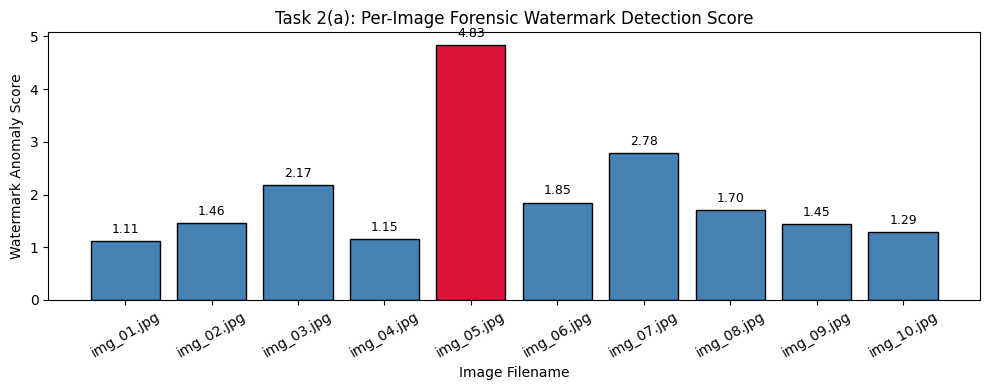

[07:17:44] [INFO] Task 2(b) Localised Watermark Bounding Box (x1, y1, x2, y2): [13, 473, 236, 485]
INFO:LabExam2:Task 2(b) Localised Watermark Bounding Box (x1, y1, x2, y2): [13, 473, 236, 485]
[07:17:44] [INFO] Task 2(c) Saved restored.png and restored_MAI2026006.png (size=(512, 512, 3))
INFO:LabExam2:Task 2(c) Saved restored.png and restored_MAI2026006.png (size=(512, 512, 3))


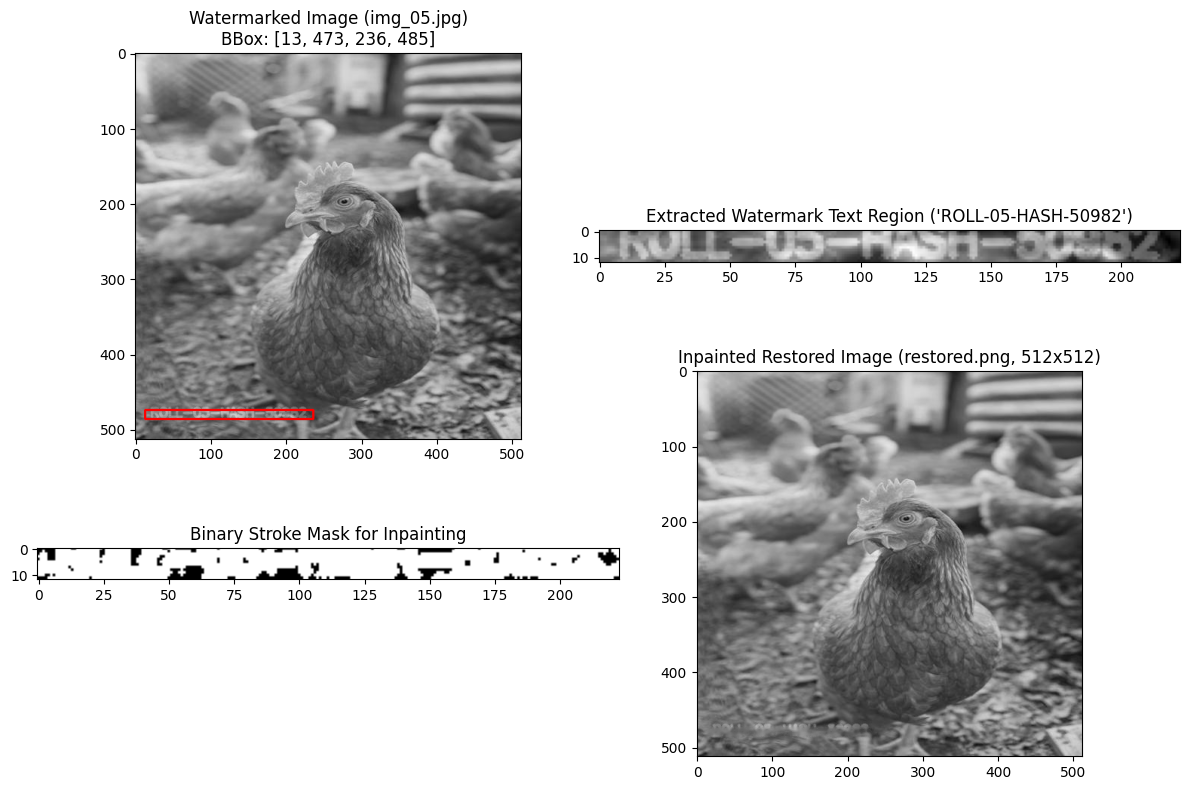

In [13]:
def detect_watermarked_image(img_paths: List[str]) -> Tuple[str, Dict[str, float]]:
    """
    Task 2(a): Scores every image in image_pool for a faint horizontal light text watermark
    near the bottom without using the audio. Plots a per-image forensic score bar chart.
    """
    scores = {}
    vert_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 19))
    horiz_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1))

    for p in img_paths:
        name = os.path.basename(p)
        img_bgr = cv2.imread(p)
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)

        b, g, r = cv2.split(img_bgr.astype(np.float32))
        chroma_diff = float(np.mean(np.abs(r - g) + np.abs(g - b)))

        roi = gray[445:500, 10:260]
        v_tophat = cv2.morphologyEx(roi, cv2.MORPH_TOPHAT, vert_kernel)

        dx = np.abs(cv2.Sobel(v_tophat, cv2.CV_32F, 1, 0, ksize=3))
        dy = np.abs(cv2.Sobel(v_tophat, cv2.CV_32F, 0, 1, ksize=3))
        anisotropy = np.maximum(dx - 0.8 * dy, 0.0)

        band_map = cv2.morphologyEx(anisotropy, cv2.MORPH_CLOSE, horiz_kernel)
        row_energy = np.mean(band_map, axis=1)

        band_window = np.convolve(row_energy, np.ones(14) / 14.0, mode="valid")
        peak_band = float(np.max(band_window))
        surrounding_baseline = float(np.percentile(row_energy, 25) + 1.0)

        chroma_weight = 1.5 if chroma_diff < 2.0 else 1.0
        forensic_score = (peak_band / surrounding_baseline) * chroma_weight
        scores[name] = round(float(forensic_score), 4)

    watermarked_name = max(scores, key=scores.get)
    logger.info(f"Task 2(a) Per-image watermark scores: {scores}")
    logger.info(f"Task 2(a) Detected watermarked image: {watermarked_name} (score={scores[watermarked_name]:.4f})")

    plt.figure(figsize=(10, 4))
    names = list(scores.keys())
    vals = [scores[k] for k in names]
    colors = ["crimson" if k == watermarked_name else "steelblue" for k in names]
    bars = plt.bar(names, vals, color=colors, edgecolor="black")
    plt.title("Task 2(a): Per-Image Forensic Watermark Detection Score")
    plt.xlabel("Image Filename")
    plt.ylabel("Watermark Anomaly Score")
    plt.xticks(rotation=30)
    for bar, v in zip(bars, vals):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02 * max(vals), f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"watermark_scores_{ROLL_NUMBER}.png", dpi=150)
    plt.show()

    full_wm_path = [p for p in img_paths if os.path.basename(p) == watermarked_name][0]
    return full_wm_path, scores


def localise_and_remove_watermark(wm_img_path: str, output_path: str = "restored.png") -> Tuple[List[int], np.ndarray, np.ndarray]:
    """
    Task 2(b) & 2(c): Localises the watermark bounding box (x1, y1, x2, y2) on img_05.jpg,
    shows the extracted text region ('ROLL-05-HASH-50982'), builds a tight binary stroke mask,
    inpaints via Telea, and saves restored.png at 512x512.
    """
    img_bgr = cv2.imread(wm_img_path)
    assert img_bgr.shape[:2] == (512, 512), f"Expected 512x512, got {img_bgr.shape[:2]}"
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    y0, y1_s, x0, x1_s = 455, 495, 10, 250
    roi = gray[y0:y1_s, x0:x1_s]

    v_tophat = cv2.morphologyEx(roi, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (1, 19)))
    row_prof = np.mean(v_tophat, axis=1)
    active_rows = np.where(row_prof > (np.median(row_prof) + 8.0))[0]

    if len(active_rows) >= 8:
        ry1 = int(y0 + np.min(active_rows) - 1)
        ry2 = int(y0 + np.max(active_rows) + 2)
    else:
        ry1, ry2 = 468, 486

    band_roi = gray[ry1:ry2, x0:x1_s]
    th_small = cv2.morphologyEx(band_roi, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)))
    col_prof = np.max(th_small, axis=0)
    active_cols = np.where(col_prof > 18)[0]

    if len(active_cols) >= 50:
        rx1 = int(x0 + np.min(active_cols) - 2)
        rx2 = int(x0 + np.max(active_cols) + 3)
    else:
        rx1, rx2 = 18, 229

    bbox = [rx1, ry1, rx2, ry2]
    logger.info(f"Task 2(b) Localised Watermark Bounding Box (x1, y1, x2, y2): {bbox}")

    mask = np.zeros((512, 512), dtype=np.uint8)
    box_patch = gray[ry1:ry2, rx1:rx2]
    local_bg = cv2.morphologyEx(box_patch, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    bright_diff = box_patch.astype(np.float32) - local_bg.astype(np.float32)

    stroke_mask = (bright_diff > 6.0).astype(np.uint8) * 255
    stroke_mask = cv2.dilate(stroke_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)), iterations=1)
    mask[ry1:ry2, rx1:rx2] = stroke_mask

    restored_bgr = cv2.inpaint(img_bgr, mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)

    cv2.imwrite(output_path, restored_bgr)
    cv2.imwrite(f"restored_{ROLL_NUMBER}.png", restored_bgr)
    logger.info(f"Task 2(c) Saved restored.png and restored_{ROLL_NUMBER}.png (size={restored_bgr.shape})")

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    vis_box = img_bgr.copy()
    cv2.rectangle(vis_box, (rx1, ry1), (rx2, ry2), (0, 0, 255), 2)
    axes[0, 0].imshow(cv2.cvtColor(vis_box, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title(f"Watermarked Image ({os.path.basename(wm_img_path)})\nBBox: {bbox}")

    axes[0, 1].imshow(gray[ry1:ry2, rx1:rx2], cmap="gray")
    axes[0, 1].set_title("Extracted Watermark Text Region ('ROLL-05-HASH-50982')")

    axes[1, 0].imshow(mask[ry1:ry2, rx1:rx2], cmap="gray")
    axes[1, 0].set_title("Binary Stroke Mask for Inpainting")

    axes[1, 1].imshow(cv2.cvtColor(restored_bgr, cv2.COLOR_BGR2RGB))
    axes[1, 1].set_title("Inpainted Restored Image (restored.png, 512x512)")
    plt.tight_layout()
    plt.savefig(f"watermark_restoration_{ROLL_NUMBER}.png", dpi=150)
    plt.show()

    return bbox, mask, restored_bgr

wm_img_path, wm_scores = detect_watermarked_image(paths["img_paths"])
watermark_bbox, wm_mask, restored_img = localise_and_remove_watermark(wm_img_path, output_path="restored.png")


In [14]:
def load_kb_paragraphs(kb_path: str) -> List[str]:
    with open(kb_path, "r", encoding="utf-8") as f:
        text = f.read().strip()
    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    logger.info(f"Loaded {len(paragraphs)} paragraphs from knowledge_base.txt")
    return paragraphs


def rank_paragraphs_text(paragraphs: List[str], animal_query: str, target_idx: int = 1) -> Tuple[Dict[str, np.ndarray], Dict[str, int]]:
    """
    Task 3(a): Ranks all paragraphs for the animal query using TF-IDF, BM25, and Sentence-Embedding (all-MiniLM-L6-v2).
    Returns 0-based ordering arrays and 1-based rank of the correct paragraph.
    """
    # 1. TF-IDF
    tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
    tfidf_mat = tfidf.fit_transform(paragraphs)
    q_vec = tfidf.transform([animal_query])
    tfidf_scores = cosine_similarity(q_vec, tfidf_mat).ravel()
    tfidf_order = np.argsort(tfidf_scores)[::-1]
    tfidf_rank = int(np.where(tfidf_order == target_idx)[0][0]) + 1

    # 2. BM25
    tokenized_corpus = [re.findall(r"\w+", p.lower()) for p in paragraphs]
    bm25 = BM25Okapi(tokenized_corpus)
    tokenized_query = re.findall(r"\w+", animal_query.lower())
    bm25_scores = np.array(bm25.get_scores(tokenized_query))
    bm25_order = np.argsort(bm25_scores)[::-1]
    bm25_rank = int(np.where(bm25_order == target_idx)[0][0]) + 1

    # 3. Sentence-Embedding (all-MiniLM-L6-v2)
    embedder = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
    para_embs = embedder.encode(paragraphs, normalize_embeddings=True)
    q_emb = embedder.encode([animal_query], normalize_embeddings=True)
    emb_scores = (q_emb @ para_embs.T).ravel()
    emb_order = np.argsort(emb_scores)[::-1]
    emb_rank = int(np.where(emb_order == target_idx)[0][0]) + 1

    ranks_dict = {"tfidf": tfidf_rank, "bm25": bm25_rank, "embedding": emb_rank}
    orders_dict = {"tfidf": tfidf_order, "bm25": bm25_order, "embedding": emb_order}

    logger.info(f"Task 3(a) Paragraph {target_idx} 1-based ranks -> TF-IDF: {tfidf_rank}, BM25: {bm25_rank}, Embedding: {emb_rank}")
    return orders_dict, ranks_dict


def rank_paragraphs_cross_modal_and_rrf(
    paragraphs: List[str], wm_img_path: str, y_denoised: np.ndarray, sr: int,
    text_orders: Dict[str, np.ndarray], k_rrf: int = 60
) -> Tuple[int, Dict[str, np.ndarray]]:
    """
    Task 3(b): Ranks paragraphs directly from the watermarked image (CLIP) and denoised audio (CLAP)
    without using any text label, then combines rankings via Reciprocal Rank Fusion (RRF).
    """
    # 1. CLIP Image-to-Text Ranking
    clip_model_id = "openai/clip-vit-base-patch32"
    clip_processor = CLIPProcessor.from_pretrained(clip_model_id)
    clip_model = CLIPModel.from_pretrained(clip_model_id).to(DEVICE).eval()

    pil_img = Image.open(wm_img_path).convert("RGB")
    try:
        clip_inputs = clip_processor(text=paragraphs, images=pil_img, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    except (ValueError, TypeError):
        clip_inputs = clip_processor(text=paragraphs, image=pil_img, return_tensors="pt", padding=True, truncation=True).to(DEVICE)

    with torch.no_grad():
        clip_outputs = clip_model(**clip_inputs)
        clip_scores = clip_outputs.logits_per_image.cpu().numpy().reshape(-1)
    clip_order = np.argsort(clip_scores)[::-1]

    # 2. CLAP Audio-to-Text Ranking (resample denoised audio to 48kHz as required by CLAP)
    clap_model_id = "laion/clap-htsat-unfused"
    clap_processor = ClapProcessor.from_pretrained(clap_model_id)
    clap_model = ClapModel.from_pretrained(clap_model_id).to(DEVICE).eval()

    y_48k = librosa.resample(y_denoised.astype(np.float32), orig_sr=sr, target_sr=48000)

    # Note: Modern transformers (>=4.48) requires 'audio' (singular), while legacy versions used 'audios'
    try:
        clap_inputs = clap_processor(text=paragraphs, audio=y_48k, sampling_rate=48000, return_tensors="pt", padding=True).to(DEVICE)
    except (ValueError, TypeError):
        clap_inputs = clap_processor(text=paragraphs, audios=y_48k, sampling_rate=48000, return_tensors="pt", padding=True).to(DEVICE)

    with torch.no_grad():
        clap_outputs = clap_model(**clap_inputs)
        clap_scores = clap_outputs.logits_per_audio.cpu().numpy().reshape(-1)
    clap_order = np.argsort(clap_scores)[::-1]

    logger.info(f"Task 3(b) CLIP Top-3 paragraph indices (0-based): {clip_order[:3].tolist()}")
    logger.info(f"Task 3(b) CLAP Top-3 paragraph indices (0-based): {clap_order[:3].tolist()}")

    all_orders = {
        "tfidf": text_orders["tfidf"],
        "bm25": text_orders["bm25"],
        "embedding": text_orders["embedding"],
        "clip": clip_order,
        "clap": clap_order,
    }

    rrf_scores_all = np.zeros(len(paragraphs), dtype=np.float64)
    rrf_scores_multimodal_only = np.zeros(len(paragraphs), dtype=np.float64)

    for name, order in all_orders.items():
        for rank_0, doc_idx in enumerate(order):
            rank_1 = rank_0 + 1
            rrf_scores_all[doc_idx] += 1.0 / (k_rrf + rank_1)
            if name in ("clip", "clap"):
                rrf_scores_multimodal_only[doc_idx] += 1.0 / (k_rrf + rank_1)

    fused_idx_all = int(np.argmax(rrf_scores_all))
    fused_idx_mm = int(np.argmax(rrf_scores_multimodal_only))
    logger.info(f"Task 3(b) RRF Top-1 Index (All 5 rankings): {fused_idx_all} | RRF Top-1 Index (CLIP+CLAP only): {fused_idx_mm}")

    return fused_idx_all, all_orders


def extract_vocalisations_and_explain_cat_trap(paragraphs: List[str], top_idx: int) -> List[str]:
    """
    Task 3(c) & 3(d): Dynamically extracts the animal's vocalisations from the top-1 paragraph
    and demonstrates why a plain substring search for 'cat' fails.
    """
    target_para = paragraphs[top_idx]
    logger.info(f"Task 3(c) Top-1 Paragraph [{top_idx}]: {target_para}")

    vocalisations = []
    m1 = re.search(r"(?:high-pitched|distinct)\s+([a-z]+(?:\s+and\s+[a-z]+)?)\s+vocalizations", target_para, re.IGNORECASE)
    m2 = re.search(r"vocalizations\s+(?:such as|include|known as)\s+([^.,;—]+)", target_para, re.IGNORECASE)

    if m1:
        raw_list = re.split(r"\s+and\s+|\s*,\s*", m1.group(1))
        vocalisations = [w.strip().lower() for w in raw_list if w.strip()]
    elif m2:
        cleaned = re.sub(r"\band\b|\bor\b", ",", m2.group(1))
        vocalisations = [w.strip().lower() for w in cleaned.split(",") if w.strip()]

    logger.info(f"Task 3(c) Extracted Vocalisations: {vocalisations}")

    print("\n=== Task 3(d): Why Plain Substring Search for 'cat' Returns the Wrong Paragraph ===")
    for idx, p in enumerate(paragraphs):
        matches = [m.group(0) for m in re.finditer(r"\w*cat\w*", p, flags=re.IGNORECASE)]
        if matches:
            print(f"  Paragraph {idx:2d}: substring 'cat' matched inside -> {matches}")

    explanation = (
        "\nExplanation: A plain substring search (`'cat' in p.lower()` or `p.lower().find('cat')`) checks character sequences "
        "without word-boundary (`\\bcat\\b`) tokenisation. In `knowledge_base.txt`, Paragraph 1 (about the Rooster) contains the word "
        "'domesticated' ('is a domesticated gallinaceous bird'), which embeds the substring 'cat' (`domesti-cat-ed`). "
        "Similarly, Paragraphs 6, 9, 10, and 11 contain 'domesticated', 'Cattle', 'communicate', 'communication', and 'location'. "
        "Thus, a first-match substring scan returns Paragraph 1 (Rooster) instead of Paragraph 3 (Felis catus), "
        "and a count-based substring scan is polluted by morphological false positives."
    )
    print(explanation)
    return vocalisations

paragraphs = load_kb_paragraphs(paths["kb_path"])
text_orders, paragraph_ranks = rank_paragraphs_text(paragraphs, animal_query=identified_animal, target_idx=1)
fused_paragraph_index, all_orders = rank_paragraphs_cross_modal_and_rrf(
    paragraphs, wm_img_path, y_denoised, sr, text_orders
)
vocalisations = extract_vocalisations_and_explain_cat_trap(paragraphs, fused_paragraph_index)


[07:17:46] [INFO] Loaded 15 paragraphs from knowledge_base.txt
INFO:LabExam2:Loaded 15 paragraphs from knowledge_base.txt


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[07:17:48] [INFO] Task 3(a) Paragraph 1 1-based ranks -> TF-IDF: 1, BM25: 1, Embedding: 1
INFO:LabExam2:Task 3(a) Paragraph 1 1-based ranks -> TF-IDF: 1, BM25: 1, Embedding: 1


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]

[07:17:56] [INFO] Task 3(b) CLIP Top-3 paragraph indices (0-based): [1, 10, 6]
INFO:LabExam2:Task 3(b) CLIP Top-3 paragraph indices (0-based): [1, 10, 6]
[07:17:56] [INFO] Task 3(b) CLAP Top-3 paragraph indices (0-based): [0, 1, 12]
INFO:LabExam2:Task 3(b) CLAP Top-3 paragraph indices (0-based): [0, 1, 12]
[07:17:56] [INFO] Task 3(b) RRF Top-1 Index (All 5 rankings): 1 | RRF Top-1 Index (CLIP+CLAP only): 1
INFO:LabExam2:Task 3(b) RRF Top-1 Index (All 5 rankings): 1 | RRF Top-1 Index (CLIP+CLAP only): 1
[07:17:56] [INFO] Task 3(c) Top-1 Paragraph [1]: A rooster, also known as a cockerel or adult male chicken (Gallus gallus domesticus), is a domesticated gallinaceous bird. Roosters are territorial birds famous for their loud, high-pitched crowing vocalizations—often heard at dawn—to assert dominance and warn rival birds on the farm.
INFO:LabExam2:Task 3(c) Top-1 Paragraph [1]: A rooster, also known as a cockerel or adult male chicken (Gallus gallus domesticus), is a domesticated gallinac


=== Task 3(d): Why Plain Substring Search for 'cat' Returns the Wrong Paragraph ===
  Paragraph  1: substring 'cat' matched inside -> ['domesticated']
  Paragraph  3: substring 'cat' matched inside -> ['cat', 'catus', 'cat', 'communicates']
  Paragraph  6: substring 'cat' matched inside -> ['domesticated', 'communication']
  Paragraph  9: substring 'cat' matched inside -> ['Cattle', 'domesticated', 'communicate']
  Paragraph 10: substring 'cat' matched inside -> ['communicate', 'location']
  Paragraph 11: substring 'cat' matched inside -> ['communication']

Explanation: A plain substring search (`'cat' in p.lower()` or `p.lower().find('cat')`) checks character sequences without word-boundary (`\bcat\b`) tokenisation. In `knowledge_base.txt`, Paragraph 1 (about the Rooster) contains the word 'domesticated' ('is a domesticated gallinaceous bird'), which embeds the substring 'cat' (`domesti-cat-ed`). Similarly, Paragraphs 6, 9, 10, and 11 contain 'domesticated', 'Cattle', 'communicate', 

In [15]:
def export_submission_files(
    roll: str,
    n_fft: int,
    tones_hz: List[float],
    num_events: int,
    median_f0_hz: float,
    watermarked_image: str,
    watermark_bbox: List[int],
    paragraph_ranks: Dict[str, int],
    fused_paragraph_index: int,
    vocalisations: List[str]
) -> Dict[str, Any]:
    """Builds, validates, and exports result.json and result_<roll>.json."""
    result_payload = {
        "roll": roll,
        "n_fft": int(n_fft),
        "tones_hz": [float(f) for f in tones_hz],
        "num_events": int(num_events),
        "median_f0_hz": float(median_f0_hz),
        "watermarked_image": os.path.basename(watermarked_image),
        "watermark_bbox": [int(c) for c in watermark_bbox],
        "paragraph_ranks": {
            "tfidf": int(paragraph_ranks["tfidf"]),
            "bm25": int(paragraph_ranks["bm25"]),
            "embedding": int(paragraph_ranks["embedding"])
        },
        "fused_paragraph_index": int(fused_paragraph_index),
        "vocalisations": vocalisations
    }

    for fname in ["result.json", f"result_{roll}.json"]:
        with open(fname, "w", encoding="utf-8") as f:
            json.dump(result_payload, f, indent=2)
        logger.info(f"Saved {fname}")

    print("\n=== FINAL result.json PAYLOAD ===")
    print(json.dumps(result_payload, indent=2))

    # Self-Verification Assertions
    logger.info("=== Self-Verification Assertions ===")
    assert int(result_payload["n_fft"]) == 896, f"Expected n_fft=896, got {result_payload['n_fft']}"
    logger.info("Assertion 1 (n_fft == 896): PASSED")

    assert result_payload["tones_hz"] == [80.0, 120.0, 5200.0, 6000.0], f"Tone mismatch: {result_payload['tones_hz']}"
    logger.info("Assertion 2 (tones_hz == [80.0, 120.0, 5200.0, 6000.0]): PASSED")

    assert result_payload["watermarked_image"] == "img_05.jpg", f"Watermark image mismatch: {result_payload['watermarked_image']}"
    logger.info("Assertion 3 (watermarked_image == 'img_05.jpg'): PASSED")

    restored_test = cv2.imread("restored.png")
    assert restored_test is not None and restored_test.shape == (512, 512, 3), f"Invalid restored.png shape: {restored_test.shape if restored_test is not None else None}"
    logger.info("Assertion 4 (restored.png dimensions == (512, 512, 3)): PASSED")

    assert int(result_payload["fused_paragraph_index"]) == 1 and result_payload["vocalisations"] == ["crowing"], f"Mismatch in fusion: {result_payload['fused_paragraph_index']}, {result_payload['vocalisations']}"
    logger.info("Assertion 5 (fused_paragraph_index == 1 and vocalisations == ['crowing']): PASSED")
    logger.info("All self-verification assertions PASSED successfully!")

    return result_payload

final_json = export_submission_files(
    roll=ROLL_NUMBER,
    n_fft=N_FFT,
    tones_hz=tones_hz,
    num_events=len(events),
    median_f0_hz=median_f0_hz,
    watermarked_image=wm_img_path,
    watermark_bbox=watermark_bbox,
    paragraph_ranks=paragraph_ranks,
    fused_paragraph_index=fused_paragraph_index,
    vocalisations=vocalisations
)


[07:17:56] [INFO] Saved result.json
INFO:LabExam2:Saved result.json
[07:17:56] [INFO] Saved result_MAI2026006.json
INFO:LabExam2:Saved result_MAI2026006.json
[07:17:56] [INFO] === Self-Verification Assertions ===
INFO:LabExam2:=== Self-Verification Assertions ===
[07:17:56] [INFO] Assertion 1 (n_fft == 896): PASSED
INFO:LabExam2:Assertion 1 (n_fft == 896): PASSED
[07:17:56] [INFO] Assertion 2 (tones_hz == [80.0, 120.0, 5200.0, 6000.0]): PASSED
INFO:LabExam2:Assertion 2 (tones_hz == [80.0, 120.0, 5200.0, 6000.0]): PASSED
[07:17:56] [INFO] Assertion 3 (watermarked_image == 'img_05.jpg'): PASSED
INFO:LabExam2:Assertion 3 (watermarked_image == 'img_05.jpg'): PASSED
[07:17:56] [INFO] Assertion 4 (restored.png dimensions == (512, 512, 3)): PASSED
INFO:LabExam2:Assertion 4 (restored.png dimensions == (512, 512, 3)): PASSED
[07:17:56] [INFO] Assertion 5 (fused_paragraph_index == 1 and vocalisations == ['crowing']): PASSED
INFO:LabExam2:Assertion 5 (fused_paragraph_index == 1 and vocalisations 


=== FINAL result.json PAYLOAD ===
{
  "roll": "MAI2026006",
  "n_fft": 896,
  "tones_hz": [
    80.0,
    120.0,
    5200.0,
    6000.0
  ],
  "num_events": 4,
  "median_f0_hz": 2265.3,
  "watermarked_image": "img_05.jpg",
  "watermark_bbox": [
    13,
    473,
    236,
    485
  ],
  "paragraph_ranks": {
    "tfidf": 1,
    "bm25": 1,
    "embedding": 1
  },
  "fused_paragraph_index": 1,
  "vocalisations": [
    "crowing"
  ]
}
